<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/The_5th_Session.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import transforms, datasets

# What do we do for implementing 2D CNN on our Dataset?

* Connecting to our Drive
* Loading our dataset
* Creating batch sets
* Definig device
* Designing our CNN model
* Train and validation loop
* Saving and Loading our model
* predicting on unseen data

> Note: This library `google.colab` is specific to Google Colab and cannot be used directly in local environments such as VS Code.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Preprocessing and Transformations

In this section, we define preprocessing operations to prepare images before feeding them into the CNN model.

- **RandomCrop:** Randomly crops a 32×32 region after adding 4 pixels of padding around the image. It helps the model generalize better by exposing it to objects at slightly different positions, making it more robust to small spatial shifts and reducing overfitting.
- **RandomHorizontalFlip:** Randomly flips images horizontally with a probability of 0.5.
- **ToTensor**: Converts the image into a PyTorch tensor, changes its dimension order from `(H, W, C)` to `(C, H, W)`, and scales pixel values from `[0, 255]` to `[0, 1]`.
- **Normalization:** Scales pixel values from [0, 1] to approximately [-1, 1] using the specified mean and standard deviation.

We use `transforms.Compose()` to combine multiple transformations into a single pipeline.

**Training Transform:** Applies data augmentation (RandomCrop and RandomHorizontalFlip), followed by tensor conversion and normalization.

**Test Transform:** Applies only tensor conversion and normalization, without data augmentation. This allows us to evaluate the model on unmodified images and measure its performance more realistically.
> Data Augmentation Increases the diversity of training samples and helps the model generalize better to unseen data. It is typically applied only to training data, not validation or test data.

> Note: Since CIFAR images have three color channels (RGB), mean and standard deviation each contain three values. Using `0.5` for all three channels is a simple and common normalization choice, but these are not necessarily the dataset's actual statistics.

In [3]:
mean, std = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

train_transform = transforms.Compose([transforms.RandomCrop(32, padding= 4),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(),
                                      transforms.Normalize(mean= mean, std= std)])


test_transform = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean= mean, std= std)])

## Loading CIFAR-100 Dataset

In this section, we load the CIFAR-100 dataset using `torchvision.datasets.CIFAR100()`.

- **DATA_DIR:** Specifies the directory where the dataset is stored.
- **Training Dataset:** Loads the 50,000 training images using `train=True` and applies training transformations, including data augmentation.
- **Validation Dataset:** Loads the same 50,000 training images using `train=True`, but applies only tensor conversion and normalization. We will later use `Subset` to select 5,000 images for validation.
- **Test Dataset:** Loads the 10,000 test images using `train=False`, without data augmentation. These images are reserved for final model evaluation.

**Note:** CIFAR-100 provides two original splits: 50,000 training images and 10,000 test images. It does not include a separate validation set, so we create one from the training data.

### Dataset Summary

| Dataset | Images | Augmentation | Purpose |
|---|---:|---|---|
| Training | 50,000 initially | Yes | Model training |
| Validation | 5,000 selected | No | Model evaluation during development |
| Test | 10,000 | No | Final model evaluation |

In [4]:
DATA_DIR= '/content/drive/MyDrive/CIFAR100_Dataset'

traindata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= train_transform)

validationdata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= test_transform)

testdata = datasets.CIFAR100(root= DATA_DIR,
                              train= False,
                              download= False,
                              transform= test_transform)

In [5]:
traindata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               RandomCrop(size=(32, 32), padding=4)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [6]:
validationdata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [7]:
testdata

Dataset CIFAR100
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

- `traindata[49999]`: Retrieves the sample at index `49999`, returning a tuple `(image, label)`.
- `traindata[49999][0]`: Retrieves the image.
- `traindata[49999][1]`: Retrieves the corresponding class label.
- `type(traindata[49999][0])`: Returns `torch.Tensor`.

**Why?** Because `ToTensor()` converts the image into a PyTorch Tensor.

**Note:** Random transformations are applied every time a sample is accessed, so the same image may look slightly different each time.

In [8]:
type(traindata[49999][0])

torch.Tensor

`traindata.targets` Returns the labels of all training images. CIFAR-100 has 100 classes, so labels range from `0` to `99`.
- `train_label[49999]` Returns the label of the sample at index `49999`.

In [9]:
train_label = traindata.targets

`traindata.data` Returns the original images without applying any transformations.
- Unlike `traindata[index]`, it does not apply the assigned transform.

In [10]:
train_image = traindata.data

In [11]:
train_image

array([[[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [195, 205, 193],
         [212, 224, 204],
         [182, 194, 167]],

        [[255, 255, 255],
         [254, 254, 254],
         [254, 254, 254],
         ...,
         [170, 176, 150],
         [161, 168, 130],
         [146, 154, 113]],

        [[255, 255, 255],
         [254, 254, 254],
         [255, 255, 255],
         ...,
         [189, 199, 169],
         [166, 178, 130],
         [121, 133,  87]],

        ...,

        [[148, 185,  79],
         [142, 182,  57],
         [140, 179,  60],
         ...,
         [ 30,  17,   1],
         [ 65,  62,  15],
         [ 76,  77,  20]],

        [[122, 157,  66],
         [120, 155,  58],
         [126, 160,  71],
         ...,
         [ 22,  16,   3],
         [ 97, 112,  56],
         [141, 161,  87]],

        [[ 87, 122,  41],
         [ 88, 122,  39],
         [101, 134,  56],
         ...,
         [ 34,  36,  10],
        

array([[[ 31,  67, 122],
        [ 30,  68, 124],
        [ 31,  69, 126],
        ...,
        [ 32,  70, 129],
        [ 32,  70, 125],
        [ 32,  69, 122]],

       [[ 29,  68, 126],
        [ 28,  69, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  70, 131],
        [ 32,  69, 127],
        [ 31,  69, 124]],

       [[ 30,  67, 126],
        [ 29,  68, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  72, 132],
        [ 31,  70, 130],
        [ 30,  69, 127]],

       ...,

       [[ 39,  41,  76],
        [ 38,  42,  76],
        [ 38,  44,  78],
        ...,
        [ 39,  44,  79],
        [ 38,  42,  77],
        [ 39,  41,  76]],

       [[ 40,  39,  73],
        [ 39,  40,  74],
        [ 39,  41,  76],
        ...,
        [ 39,  41,  76],
        [ 40,  41,  74],
        [ 40,  39,  73]],

       [[ 40,  39,  70],
        [ 40,  39,  71],
        [ 40,  39,  72],
        ...,
        [ 41,  38,  72],
        [ 39,  38,  69],
        [ 40,  37,  67]]], dtype=uint8)
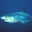

In [12]:
train_image[49999]

In [13]:
train_image[49999].shape

(32, 32, 3)

In [14]:
type(train_image[49999])

numpy.ndarray

array([[[141, 134, 115],
        [167, 160, 142],
        [161, 154, 137],
        ...,
        [ 59,  49,  38],
        [ 44,  34,  23],
        [ 80,  70,  60]],

       [[107,  99,  85],
        [146, 139, 121],
        [153, 147, 124],
        ...,
        [ 40,  30,  18],
        [103,  94,  81],
        [165, 155, 143]],

       [[ 71,  64,  49],
        [112, 105,  87],
        [120, 114,  91],
        ...,
        [ 96,  87,  72],
        [154, 145, 130],
        [180, 170, 155]],

       ...,

       [[119, 112,  94],
        [ 92,  86,  68],
        [ 79,  72,  54],
        ...,
        [147, 138, 121],
        [ 95,  86,  69],
        [ 59,  50,  33]],

       [[130, 122, 104],
        [114, 107,  89],
        [ 84,  77,  59],
        ...,
        [ 71,  62,  45],
        [ 52,  43,  26],
        [ 81,  72,  55]],

       [[141, 133, 115],
        [122, 115,  98],
        [106,  99,  81],
        ...,
        [ 66,  57,  40],
        [ 98,  89,  72],
        [140, 131, 114]]], dtype=uint8)
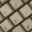

In [15]:
train_image[4999]

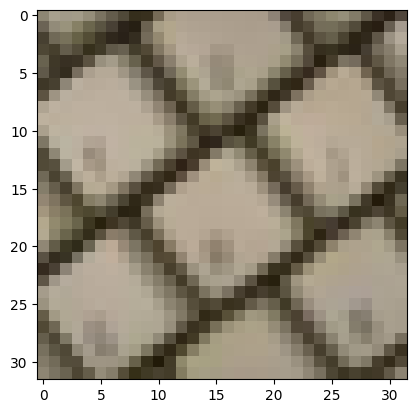

In [16]:
plt.imshow(train_image[4999])

In [17]:
train_image.shape

(50000, 32, 32, 3)

In [18]:
train_image.shape[0]

50000

## Splitting Training and Validation Data

We split the original 50,000 training images into:
- **Training:** 45,000 samples
- **Validation:** 5,000 samples

**Creating a Generator:**
- `torch.Generator()` Creates a random number generator.
- `manual_seed(42)` Ensures reproducibility by generating the same random sequence across runs under the same conditions.

**Generating Random Indices:**
- `torch.randperm()` Generates a random permutation of integers from `0` to `49,999`.
- `generator=generator` Uses our predefined generator and seed.

**Selecting Training Indices:**
- `indices[:45000]` Selects the first 45,000 indices.
- `.tolist()` Converts the Tensor into a Python list.

**Selecting Validation Indices:**
- `indices[45000:]` Selects the remaining 5,000 indices.
- `.tolist()` Converts them into a Python list.

> **Note:** Both subsets are randomly selected without overlap, ensuring that each sample belongs to either the training or validation set.

In [19]:
generator = torch.Generator().manual_seed(42)
indices= torch.randperm(train_image.shape[0], generator= generator)
indices

tensor([37542, 44491,   216,  ..., 40730, 25847, 33082])

In [20]:
train_indices = indices[:45000].tolist()
validaion_indices = indices[45000:].tolist()
type(train_indices)

list

## Creating Training and Validation Subsets

We use `Subset()` to create two smaller datasets from the original datasets using the selected indices.

- **Training Subset:** Selects 45,000 samples from `traindata`, applying `train_transform` (including data augmentation).
- **Validation Subset:** Selects 5,000 samples from `validationdata`, applying `test_transform` (without data augmentation).

> **Important:** The validation subset must be created from `validationdata`, not `traindata`, to ensure that random data augmentation is not applied during validation.

In [21]:
train_data = Subset(traindata, train_indices)
val_data = Subset(validationdata, validaion_indices)

## Creating DataLoaders

`DataLoader()` divides datasets into smaller batches for efficient training and evaluation.

- **batch_size=128:** Processes 128 images per batch. The training set contains 352 batches per epoch.
- **shuffle=True:** Randomly changes the sample order in each epoch to prevent learning from a fixed data order.

**TestLoader:**
Loads 10,000 test images in batches of 128. `shuffle=False` keeps their order unchanged.

**ValidationLoader:**
Loads 5,000 validation images in batches of 128, also with `shuffle=False`.

| DataLoader | Samples | Shuffle |
|---|---:|---|
| TrainLoader | 45,000 | True |
| ValidationLoader | 5,000 | False |
| TestLoader | 10,000 | False |

In [22]:
TrainLoader = DataLoader(train_data, batch_size= 128, shuffle= True)
TestLoader = DataLoader(testdata, batch_size= 128, shuffle= False)
ValidationLoader = DataLoader(val_data, batch_size= 128, shuffle= False)

🈁

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

**1. Padding**

Padding adds extra pixels (usually zeros) around the input to control the output dimensions.

- Padding formula:
$$
P = \frac{K-1}{2}
$$

  This preserves the input size when stride = 1 (for odd-sized kernels).

- Example:

  If the input contains 8 pixels and padding = 1:

$$
0 \quad x_1 \quad x_2 \quad x_3 \quad x_4 \quad x_5 \quad x_6 \quad x_7 \quad x_8 \quad 0
$$

  One zero is added to each side.

**2. Stride**

Stride determines how many pixels the filter moves at each step.

- Stride = 1: The filter moves one pixel at a time.
- Stride = 2: The filter moves two pixels at a time, reducing the spatial dimensions.

Using stride = 2 can perform downsampling without requiring a separate pooling layer.

**3. Output Size Formula**

General Formula (with Dilation):
$$
L_{out} = \left\lfloor \frac{L_{in}+2P-D(K-1)-1}{S} \right\rfloor + 1
$$

Simplified Formula (when D = 1):
$$
L_{out} = \left\lfloor \frac{L_{in}-K+2P}{S} \right\rfloor + 1
$$

Where:

- `L_in`: Input length
- `L_out`: Output length
- `K`: Kernel size
- `P`: Padding
- `S`: Stride
- `D`: Dilation


> **Important Notes**
> - When stride = 1 and padding = (K - 1) / 2, the output size remains equal to the input size (for odd-sized kernels).
> - When stride = 2, the output dimensions are approximately halved.
> - Stride = 2 can replace a separate downsampling operation, depending on the architecture.
> - Padding = 0 means no extra pixels are added (Valid Padding).
> - Padding = (K - 1) / 2 with stride = 1 is commonly called Same Padding.


---



### Fully Connected (FC) Layers

The FC layers receive the features extracted by the Convolutional layers and use them for classification.

- **Flatten:** Converts the feature maps from `(Batch, Channels, Height, Width)` into `(Batch, Features)`. For example: `(128, 256, 4, 4) → (128, 4096)`.

- **Linear(4096, 128):** Combines the 4096 input features into 128 output features using learnable weights and biases.

- **ReLU:** Introduces non-linearity, allowing the network to learn more complex patterns.

- **Dropout(p=0.2):** Randomly disables 20% of neurons during training to reduce overfitting. It is disabled during evaluation.

- **Linear(128, num_classes):** Produces one logit per class. For CIFAR-100, the output contains 100 logits per image.

**Note:** The number of hidden neurons (128) and the Dropout rate (0.2) are design choices and can be adjusted through experimentation.
> Why two layers? The ReLU between them allows the network to learn more complex, non-linear patterns.
> - First Linear (4096 → 128): Combines extracted features into a compact representation.
> - Second Linear (128 → 100): Maps these features to class scores (logits) for classification.



In [24]:
class CNN2D(nn.Module):
  def __init__(self, in_channels, num_classes):
    super(CNN2D, self).__init__()

    self.Blocks = nn.Sequential(nn.Conv2d(in_channels= in_channels, out_channels= 64, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 64),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2),

                              nn.Conv2d(in_channels= 64, out_channels= 128, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 128),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2),

                              nn.Conv2d(in_channels= 128, out_channels= 256, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 256),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2))

    self.FC = nn.Sequential(nn.Flatten(),
                            nn.Linear(256*4*4, 128),
                            nn.ReLU(),
                            nn.Dropout(p= 0.2),
                            nn.Linear(128, num_classes))
  def forward(self, x):
    x = self.Blocks(x)
    x = self.FC(x)

    return x

- `torch.manual_seed(42)`: Sets the random seed to make experiments more reproducible.

- `CNN2D(3, 100)`: Creates a CNN2D model with 3 input channels (RGB) and 100 output classes.

- `.to(device)`: Moves the model to the specified device (CPU or GPU).

In [25]:
torch.manual_seed(42)

CNN_Model = CNN2D(3, 100).to(device)
CNN_Model

CNN2D(
  (Blocks): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (FC): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, in

This line calculates the total number of parameters in the CNN model.

- `CNN_Model.parameters()`: Returns all model parameters (weights and biases).
- `p.numel()`: Counts the number of elements in each parameter tensor.
- `sum()`: Adds them all together.

Output: Total number of trainable and non-trainable parameters in the model (if any).

In [26]:
total_para = sum(p.numel() for p in CNN_Model.parameters())
total_para

909028

`CNN_Model.state_dict()` returns a dictionary containing the model's parameters (weights and biases) and registered buffers, such as BatchNorm statistics.

Purpose: Used to save and load the model's learned parameters.

In [27]:
CNN_Model.state_dict()

OrderedDict([('Blocks.0.weight',
              tensor([[[[ 0.1471,  0.1597, -0.0451],
                        [ 0.1768, -0.0422,  0.0388],
                        [-0.0937,  0.1130,  0.1697]],
              
                       [[-0.1412,  0.1673,  0.0360],
                        [ 0.1422,  0.0261,  0.0928],
                        [-0.0272,  0.1484,  0.0284]],
              
                       [[-0.0898,  0.0491, -0.0887],
                        [-0.0226, -0.0782,  0.1277],
                        [-0.1519, -0.0887, -0.0543]]],
              
              
                      [[[-0.1157,  0.0182, -0.1901],
                        [ 0.1738, -0.1635,  0.1486],
                        [ 0.0320, -0.0625,  0.1189]],
              
                       [[ 0.0300,  0.1555,  0.0210],
                        [-0.0607,  0.0517, -0.0522],
                        [ 0.0810,  0.1718,  0.1112]],
              
                       [[-0.0841,  0.1111,  0.0344],
                       

## Setup loss and optimizer

- `nn.CrossEntropyLoss()`: Computes the classification loss by comparing the predicted logits with the ground-truth labels. It combines LogSoftmax and Negative Log-Likelihood Loss.

- `optim.SGD()`: Creates an optimizer using Stochastic Gradient Descent to update the model's parameters and minimize the loss.

  - `CNN_Model.parameters()`: Provides the model's trainable parameters (weights and biases) to the optimizer.
  - `lr = 0.001`: Sets the learning rate, controlling the step size of parameter updates.
  - `momentum = 0.9`: Uses information from previous gradients to accelerate convergence and reduce oscillations.


### Momentum vs. Weight Decay

- **Momentum:** Uses gradients from previous steps to improve the direction and speed of parameter updates.
- **Weight Decay:** Penalizes large weights to reduce overfitting and improve generalization.

These two techniques have different purposes and are not direct replacements for each other. They can also be used together:

- `momentum=0.9`: Helps make optimization faster and more stable.
- `weight_decay=0.0001`: Adds regularization by penalizing large weights.

In [28]:
loss = nn.CrossEntropyLoss()
optimizer = optim.SGD(CNN_Model.parameters(), lr= 0.001, momentum= 0.9)

## Train and Validation loop

This loop trains the CNN model using batches of training data. It performs forward propagation, calculates the loss, updates model parameters, and tracks training performance.

**1. Set Random Seed:**
`torch.manual_seed(42)`
Ensures reproducibility by controlling PyTorch's random operations.

**2. Set Training Mode:**
`CNN_Model.train()`
Enables training behavior for layers such as Dropout and BatchNorm.

**3. Initialize Metrics:**
`train_loss, train_total, train_correct = 0, 0, 0`
Initializes variables to track the total loss, number of processed samples, and correct predictions.

**4. Load Training Batches:**
`for x, y in TrainLoader:`
Iterates through the training dataset in batches:
- `x`: Input images.
- `y`: Ground-truth labels.

**5. Move Data to Device:** `x, y = x.to(device), y.to(device)`
Moves input images and labels to the selected device (CPU or GPU).

**6. Forward Pass:**
`
tr_out = CNN_Model(x)
`
Passes input images through the CNN to generate class logits.

**7. Calculate Loss:**
`
trainloss = loss(tr_out, y)
`
Measures the difference between the predicted logits and the true labels.

**8. Get Predicted Classes:**
`
_, tr_pre = torch.max(tr_out, dim=1)
`
Returns the index of the highest logit for each image, representing the predicted class.

**9. Update Model Parameters:**
`optimizer.zero_grad()`
`trainloss.backward()`
`optimizer.step()`

- `zero_grad()`: Clears previously accumulated gradients.
- `backward()`: Computes gradients using backpropagation.
- `step()`: Updates model parameters using the optimizer.

**10. Track Training Metrics:**

`train_loss += trainloss.item()`

`train_total += tr_out.size(0)`

`train_correct += (tr_pre == y).sum().item()`

Accumulates the batch loss, number of processed samples, and number of correct predictions.

**11. Calculate Training Accuracy:**
`
train_accuracy = 100 * (train_correct / train_total)
`
Calculates the percentage of correctly classified training samples.

In [29]:
torch.manual_seed(42)

CNN_Model.train()
train_loss, train_total, train_correct = 0, 0, 0

for x, y in TrainLoader:

  x, y = x.to(device), y.to(device)
  tr_out = CNN_Model(x)
  trainloss = loss(tr_out, y)

  _, tr_pre = torch.max(tr_out, dim= 1)


  optimizer.zero_grad()
  trainloss.backward()
  optimizer.step()

  train_loss += trainloss.item()
  train_total += tr_out.size(0)
  train_correct += (tr_pre == y).sum().item()


train_accuracy = 100*(train_correct/train_total)